# Build a custom diffusion equation

Here we define a new equation in the notebook and pass it to `PDEModel`. We will follow a pulse of concentration $u$ as it spreads on a periodic interval according to $\partial_t u = D\,\partial_{xx}u$, where $D$ is a positive, constant diffusivity. Periodic diffusion preserves the total amount of material, giving us a way to check our implementation.

Run this tutorial in an environment with [mosaix-pde installed](https://github.com/acoh64/mosaix-pde#installation).

In [1]:
import diffrax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from mosaix_pde import BaseEquation, Domain, PDEModel

## Define the equation

Subclass `BaseEquation` and give the constructor a `domain` argument plus a keyword for each physical parameter. Here the domain supplies the grid spacing and the only parameter is `diffusivity`.

Implement `rhs(state, t)` to return the time derivative at every grid point, with the same shape as `state`. This equation has no explicit time dependence, so it accepts `t` without using it. The centered difference uses the two neighboring concentrations. Rolling the array wraps the last point around to the first, which imposes the periodic boundary condition.

In [2]:
class PeriodicDiffusion1D(BaseEquation):
    """Diffusion on a uniform one-dimensional periodic grid."""

    def __init__(self, domain, diffusivity):
        self.dx = domain.dx[0]
        self.diffusivity = diffusivity

    def rhs(self, state, t):
        left = jnp.roll(state, 1)
        right = jnp.roll(state, -1)
        laplacian = (left - 2 * state + right) / self.dx**2
        return self.diffusivity * laplacian

## Solve for a localized pulse

Pass the equation **class** to `PDEModel`. Each call to `solve` constructs the equation with the domain and the entries in `parameters`, so the dictionary keys must match the constructor arguments. Diffrax's explicit Tsit5 solver only needs the right-hand side implemented above.

Here we save three profiles on a uniform grid. We choose a small fixed time step proportional to $\Delta x^2/D$ so the explicit diffusion solve remains stable as the grid spacing changes.

In [3]:
domain = Domain(points=(64,), box=((0.0, 1.0),), units="dimensionless")
(x,) = domain.axes()
initial = jnp.exp(-0.5 * ((x - 0.5) / 0.06) ** 2)
diffusivity = 0.05
times = jnp.array([0.0, 0.02, 0.05])

model = PDEModel(PeriodicDiffusion1D, domain, diffrax.Tsit5)
solution = model.solve(
    parameters={"diffusivity": diffusivity},
    y0=initial,
    ts=times,
    dt0=0.2 * domain.dx[0] ** 2 / diffusivity,
)

## Check the solution

The peak should fall and the pulse should broaden. The mean concentration should stay constant because material leaving one end of the periodic grid re-enters at the other.

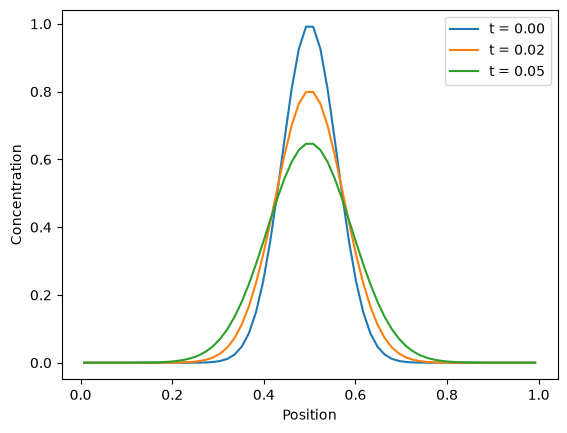

In [4]:
_, ax = plt.subplots()
for time, profile in zip(times, solution):
    ax.plot(x, profile, label=f"t = {float(time):.2f}")
ax.set(xlabel="Position", ylabel="Concentration")
ax.legend()
plt.show()

In [5]:
means = solution.mean(axis=1)
print("Mean concentration at each saved time:", means)
assert jnp.allclose(means, initial.mean(), atol=1e-6, rtol=0)
assert solution[-1].max() < solution[0].max()

Mean concentration at each saved time: [0.15039764 0.15039766 0.15039766]


To model diffusion with decay, add a `decay_rate` parameter to the constructor, store it on the equation, and subtract `self.decay_rate * state` from the right-hand side. Pass `decay_rate` alongside `diffusivity` when calling `solve`. With positive decay, the mean concentration should now decrease, so update the conservation check accordingly.